# Predict

### Load Model

In [44]:
import os

# Set Keras backend explicitly to PyTorch and target your MIG GPU
os.environ['PYTORCH_NVML_BASED_CUDA_CHECK'] = '1'
os.environ['CUDA_DEVICE_ORDER'] = 'PCI_BUS_ID'
os.environ['CUDA_VISIBLE_DEVICES'] = '0'
os.environ['KERAS_BACKEND'] = 'torch'

from parameters import *
import numpy as np

# Import load_model directly from keras (not tensorflow.keras)
from keras.models import load_model
from pathlib import Path
home = Path.home()

In [45]:
import keras
import torch
print("--- Environment Validation ---")
print(f"Active Keras Backend: {keras.backend.backend()}")
print(f"PyTorch CUDA Available: {torch.cuda.is_available()}")

print("\n--- Hardware Validation ---")
if torch.cuda.is_available():
    print(f"Device Count: {torch.cuda.device_count()}")
    print(f"Device Name: {torch.cuda.get_device_name(0)}")
    
    # 2. Force a micro-computation to ensure libraries aren't just visible, but working
    try:
        print("\nAttempting to push a tensor to the GPU...")
        test_tensor = torch.tensor([1.0, 2.0, 3.0]).cuda()
        test_result = test_tensor * 2
        print(f"Result on GPU: {test_result}")
        print("✅ SUCCESS: The GPU is fully operational and ready for training!")
    except Exception as e:
        print(f"❌ FAILED during computation. Error: {e}")
else:
    print("❌ FAILED: PyTorch cannot see the GPU.")

--- Environment Validation ---
Active Keras Backend: torch
PyTorch CUDA Available: True

--- Hardware Validation ---
Device Count: 1
Device Name: NVIDIA A100 80GB PCIe MIG 4g.40gb

Attempting to push a tensor to the GPU...
Result on GPU: tensor([2., 4., 6.], device='cuda:0')
✅ SUCCESS: The GPU is fully operational and ready for training!


In [67]:
if KERAS_TUNER: 
    best_model_file ='newest100k_model.keras'#'model/best_model.keras'
else:
    # Define shape based on parameters file neurons
    model_shape = 'mlp_602_'
    model_shape += '_'.join(str(l) for l in NEURONS_PER_LAYER)
    model_shape += '_10'

    best_model_file = 'model/{}_best_model.keras'.format(model_shape)
                                                       

In [68]:
print(best_model_file)

newest100k_model.keras


In [69]:
#importing iv loss
def physical_iv_loss(y_true, y_pred):
    # 1. Unscale from [0, 1] back to natural log space
    MIN_LOG = -16.11809565095832
    MAX_LOG = -5.066905776264235
    MIN_LIN = 1e-7
    y_true_log = y_true * (MAX_LOG - MIN_LOG) + MIN_LOG
    y_pred_log = y_pred * (MAX_LOG - MIN_LOG) + MIN_LOG
    
    # 2. Convert natural log to physical Amperes using Keras ops
    y_true_amps = ops.exp(y_true_log)
    y_pred_amps = ops.exp(y_pred_log)
    
    # 3. Apply the 1e-7 A floor
    y_true_floored = ops.maximum(y_true_amps, MIN_LIN)
    y_pred_floored = ops.maximum(y_pred_amps, MIN_LIN)
    
    # 4. Compute log-MSE loss across decades
    error = ops.log(y_pred_floored) - ops.log(y_true_floored)
    return ops.mean(ops.square(error))

# Include your custom function in a dictionary

model = load_model(
    best_model_file,
    custom_objects={"physical_iv_loss": physical_iv_loss},
    compile=False,
)

## Process Measurements

### Load data

In [70]:
import csv
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

In [71]:
#filename = 'test_measurements/rvtnMeasurementData.csv'
filename = f'{home}/Skywater-130nm-77K-Cryogenic-Models/cryo_data/nmos_FET_len_0p15_wid_1p6/idvg_Vd1p48.csv'
df = pd.read_csv(filename)
dataId = df.iloc[:, 2].to_numpy()
dataVg = df.iloc[:, 1].to_numpy()  

In [72]:
# Load test data for comparison
X_test = np.asarray(np.load('{}/npy/x_{}_test_augmented.npy'.format(DATA_DIR, PARAM), allow_pickle=True))

In [73]:
# Load test data for comparison
y_test = np.asarray(np.load('{}/npy/y_{}_test_augmented.npy'.format(DATA_DIR, PARAM), allow_pickle=True))

In [74]:
# Ensure Vg values are the same as training data
print('Measurement Vg 1: ', dataVg[0], 'Training/test Vg 1: ', X_test[0][0][0])
print('Measurement Vg Len: ', len(dataVg), 'Training/test Vg Len: ', len(X_test[0][0]))
print('Measurement Vg 185: ', dataVg[185], 'Training/test Vg 300: ', X_test[185][0])

Measurement Vg 1:  0.0 Training/test Vg 1:  0.01
Measurement Vg Len:  186 Training/test Vg Len:  185
Measurement Vg 185:  1.85 Training/test Vg 300:  [0.01, 0.02, 0.03, 0.04, 0.05, 0.06, 0.07, 0.08, 0.09, 0.1, 0.11, 0.12, 0.13, 0.14, 0.15, 0.16, 0.17, 0.18, 0.19, 0.2, 0.21, 0.22, 0.23, 0.24, 0.25, 0.26, 0.27, 0.28, 0.29, 0.3, 0.31, 0.32, 0.33, 0.34, 0.35, 0.36, 0.37, 0.38, 0.39, 0.4, 0.41, 0.42, 0.43, 0.44, 0.45, 0.46, 0.47, 0.48, 0.49, 0.5, 0.51, 0.52, 0.53, 0.54, 0.55, 0.56, 0.57, 0.58, 0.59, 0.6, 0.61, 0.62, 0.63, 0.64, 0.65, 0.66, 0.67, 0.68, 0.69, 0.7, 0.71, 0.72, 0.73, 0.74, 0.75, 0.76, 0.77, 0.78, 0.79, 0.8, 0.81, 0.82, 0.83, 0.84, 0.85, 0.86, 0.87, 0.88, 0.89, 0.9, 0.91, 0.92, 0.93, 0.94, 0.95, 0.96, 0.97, 0.98, 0.99, 1.0, 1.01, 1.02, 1.03, 1.04, 1.05, 1.06, 1.07, 1.08, 1.09, 1.1, 1.11, 1.12, 1.13, 1.14, 1.15, 1.16, 1.17, 1.18, 1.19, 1.2, 1.21, 1.22, 1.23, 1.24, 1.25, 1.26, 1.27, 1.28, 1.29, 1.3, 1.31, 1.32, 1.33, 1.34, 1.35, 1.36, 1.37, 1.38, 1.39, 1.4, 1.41, 1.42, 1.43, 1.44,

### Transform Data

Here we will set everything below the noise floor to 0, and log scale just like what was done for training data

In [75]:
# Set values below measurement noise floor to global_min, So we prepare the model for the input measurement data
if MYSTIC_MC:
    noiseFloor = -1e-7 #for 0.15 1.6 nmos
    
    filename = f'{home}/Skywater-130nm-77K-Cryogenic-Models/cryo_data/nmos_FET_len_0p15_wid_1p6/idvg_Vd1p48.csv'

    df = pd.read_csv(filename)
    dataId_meas = df.iloc[:, 2].to_numpy()
    
    dataId_meas = np.where(dataId_meas < noiseFloor, 0, dataId_meas)
    valid_values = dataId_meas[dataId_meas != 0]
    global_min = np.min(valid_values)
 
    dataId = np.where(dataId < noiseFloor, global_min, dataId)
else:
    noiseFloor = 1e-7  #for 0.15 1.6 nmos
    
    # find minimum value for data we want to measure and set that to minimum so it doesnt learn any misleading information
    #filename = 'test_measurements/rvtnMeasurementData.csv'
    filename = f'{home}/Skywater-130nm-77K-Cryogenic-Models/cryo_data/nmos_FET_len_0p15_wid_1p6/idvg_Vd1p48.csv'

    #df = pd.read_csv(filename)
    #dataId_meas = df.iloc[:, 2].to_numpy()
    df = pd.read_csv(filename)
    dataId_meas = df.iloc[:, 2].to_numpy()

# 1. Clean up any extreme drops or negative leakage artifacts by clamping directly to your floor
    dataId_meas = np.where(dataId_meas < noiseFloor, noiseFloor, dataId_meas)

# 2. Extract valid values above the floor to calculate metrics if needed
    valid_values = dataId_meas[dataId_meas > noiseFloor]
    if len(valid_values) > 0:
        global_min = np.min(valid_values)
    else:
        global_min = noiseFloor
    
    #dataId_meas = np.where(dataId_meas < noiseFloor, 0, dataId_meas)
    #valid_values = dataId_meas[dataId_meas != 0]
    #global_min = np.min(valid_values)
 
    dataId = np.where(dataId < noiseFloor, global_min, dataId)

In [76]:
# Log scale
dataId_log = np.log(dataId)
print(dataId)

[3.0000e-07 3.0000e-07 3.0000e-07 3.0000e-07 3.0000e-07 3.0000e-07
 3.0000e-07 3.0000e-07 3.0000e-07 3.0000e-07 3.0000e-07 3.0000e-07
 3.0000e-07 3.0000e-07 3.0000e-07 3.0000e-07 3.0000e-07 3.0000e-07
 3.0000e-07 3.0000e-07 3.0000e-07 3.0000e-07 3.0000e-07 3.0000e-07
 3.0000e-07 3.0000e-07 3.0000e-07 3.0000e-07 3.0000e-07 3.0000e-07
 3.0000e-07 3.0000e-07 3.0000e-07 3.0000e-07 3.0000e-07 3.0000e-07
 3.0000e-07 3.0000e-07 3.0000e-07 3.0000e-07 3.0000e-07 3.0000e-07
 3.0000e-07 3.0000e-07 3.0000e-07 3.0000e-07 3.0000e-07 3.0000e-07
 3.0000e-07 3.0000e-07 3.0000e-07 3.0000e-07 3.0000e-07 3.0000e-07
 3.0000e-07 3.0000e-07 3.0000e-07 3.0000e-07 3.0000e-07 3.0000e-07
 1.0000e-07 1.0000e-07 1.0000e-07 3.0000e-07 4.0000e-07 7.0000e-07
 1.0000e-06 1.6000e-06 2.2000e-06 3.3000e-06 4.5000e-06 5.9000e-06
 7.9000e-06 1.0200e-05 1.3200e-05 1.9100e-05 2.0100e-05 2.4500e-05
 2.9300e-05 3.4500e-05 4.0200e-05 4.6600e-05 5.3400e-05 6.1100e-05
 6.8800e-05 7.5200e-05 8.4300e-05 9.3700e-05 1.0220e-04 1.1330

### Scale Data

In [77]:
# Need to import scaling function, open terminal--> pip install import_ipynb
import import_ipynb
from ml_custom_scaler import Scaler

In [78]:
scaler = Scaler()

In [79]:
# Grab scaling Values we used for all of the training data

filename = 'scaling_boundaries.txt'
with open(filename, 'r') as file:
        boundaries = {}
        
        for line in file:
            key_value = line.strip().split(': ')
            if len(key_value) == 2:
                key = key_value[0] 
                value = float(key_value[1]) 
                boundaries[key] = value 

min_lin = boundaries['min_lin']
max_lin = boundaries['max_lin']
min_log = boundaries['min_log']
max_log = boundaries['max_log']

print("Min Linear:", min_lin)
print("Max Linear:", max_lin)
print("Min Log:", min_log)
print("Max Log:", max_log)

Min Linear: 1e-07
Max Linear: 0.00532901384
Min Log: -16.11809565095832
Max Log: -5.234589078560712


In [80]:
# Use these values to scale the measurement data

dataId_scaled, global_min, global_max = scaler.scale(dataId, global_min=float(min_lin), global_max=float(max_lin))
dataId_scaled_log, global_min_log, global_max_log = scaler.scale(dataId_log, global_min=float(min_log), global_max=float(max_log))

Using provided global min: 1e-07
Using provided global max: 0.00532901384
Using provided global min: -16.11809565095832
Using provided global max: -5.234589078560712


In [81]:
print(dataId)

[3.0000e-07 3.0000e-07 3.0000e-07 3.0000e-07 3.0000e-07 3.0000e-07
 3.0000e-07 3.0000e-07 3.0000e-07 3.0000e-07 3.0000e-07 3.0000e-07
 3.0000e-07 3.0000e-07 3.0000e-07 3.0000e-07 3.0000e-07 3.0000e-07
 3.0000e-07 3.0000e-07 3.0000e-07 3.0000e-07 3.0000e-07 3.0000e-07
 3.0000e-07 3.0000e-07 3.0000e-07 3.0000e-07 3.0000e-07 3.0000e-07
 3.0000e-07 3.0000e-07 3.0000e-07 3.0000e-07 3.0000e-07 3.0000e-07
 3.0000e-07 3.0000e-07 3.0000e-07 3.0000e-07 3.0000e-07 3.0000e-07
 3.0000e-07 3.0000e-07 3.0000e-07 3.0000e-07 3.0000e-07 3.0000e-07
 3.0000e-07 3.0000e-07 3.0000e-07 3.0000e-07 3.0000e-07 3.0000e-07
 3.0000e-07 3.0000e-07 3.0000e-07 3.0000e-07 3.0000e-07 3.0000e-07
 1.0000e-07 1.0000e-07 1.0000e-07 3.0000e-07 4.0000e-07 7.0000e-07
 1.0000e-06 1.6000e-06 2.2000e-06 3.3000e-06 4.5000e-06 5.9000e-06
 7.9000e-06 1.0200e-05 1.3200e-05 1.9100e-05 2.0100e-05 2.4500e-05
 2.9300e-05 3.4500e-05 4.0200e-05 4.6600e-05 5.3400e-05 6.1100e-05
 6.8800e-05 7.5200e-05 8.4300e-05 9.3700e-05 1.0220e-04 1.1330

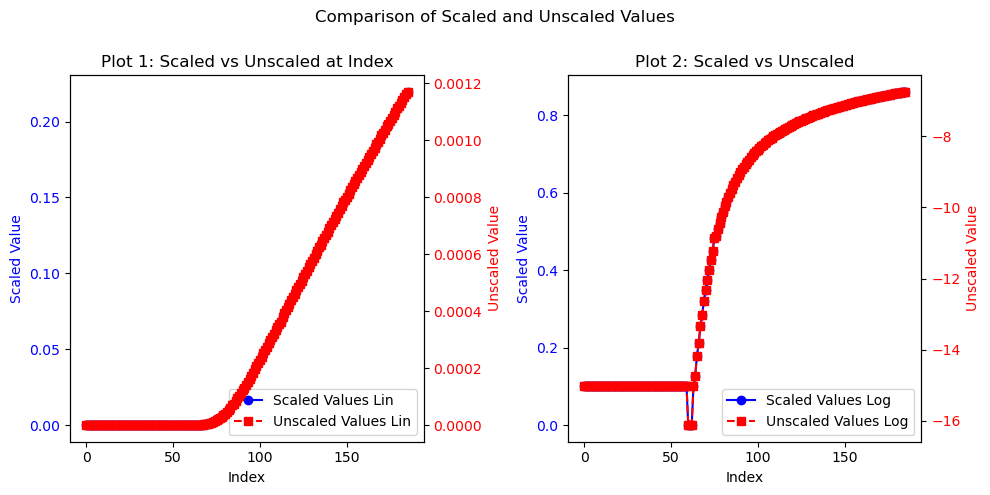

In [82]:
# Plot the scaled vs unscaled list 
# Assuming scaled_x and X_drain_current are pre-defined DataFrames

sample_scaled_values_1 = dataId_scaled
sample_unscaled_values_1 = dataId

# Create a new set of sample data for the second plot
sample_scaled_values_2 = dataId_scaled_log
sample_unscaled_values_2 = dataId_log

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 5))

# First plot
line1_1, = ax1.plot(sample_scaled_values_1, marker='o', linestyle='-', color='b', label='Scaled Values Lin')
ax1.set_xlabel('Index')
ax1.set_ylabel('Scaled Value', color='b')
ax1.tick_params(axis='y', labelcolor='b')
ax1_twin = ax1.twinx()

line1_2, = ax1_twin.plot(sample_unscaled_values_1, marker='s', linestyle='--', color='r', label='Unscaled Values Lin')
ax1_twin.set_ylabel('Unscaled Value', color='r')
ax1_twin.tick_params(axis='y', labelcolor='r')

lines_1 = [line1_1, line1_2]
ax1.legend(lines_1, [line.get_label() for line in lines_1], loc='lower right')
ax1.set_title('Plot 1: Scaled vs Unscaled at Index')

# Second plot
line2_1, = ax2.plot(sample_scaled_values_2, marker='o', linestyle='-', color='b', label='Scaled Values Log')
ax2.set_xlabel('Index')
ax2.set_ylabel('Scaled Value', color='b')
ax2.tick_params(axis='y', labelcolor='b')
ax2_twin = ax2.twinx()

line2_2, = ax2_twin.plot(sample_unscaled_values_2, marker='s', linestyle='--', color='r', label='Unscaled Values Log')
ax2_twin.set_ylabel('Unscaled Value', color='r')
ax2_twin.tick_params(axis='y', labelcolor='r')

lines_2 = [line2_1, line2_2]
ax2.legend(lines_2, [line.get_label() for line in lines_2], loc='lower right')
ax2.set_title('Plot 2: Scaled vs Unscaled')

plt.tight_layout()
plt.suptitle('Comparison of Scaled and Unscaled Values')
plt.subplots_adjust(top=0.85)  
plt.show()

In [83]:
# Append log scale to end of lin scale data
lin_log_measurements = np.concatenate([dataId_scaled, dataId_scaled_log])
print(lin_log_measurements.shape)


(372,)


In [84]:
print(lin_log_measurements)
print(lin_log_measurements[185])

[3.75311003e-05 3.75311003e-05 3.75311003e-05 3.75311003e-05
 3.75311003e-05 3.75311003e-05 3.75311003e-05 3.75311003e-05
 3.75311003e-05 3.75311003e-05 3.75311003e-05 3.75311003e-05
 3.75311003e-05 3.75311003e-05 3.75311003e-05 3.75311003e-05
 3.75311003e-05 3.75311003e-05 3.75311003e-05 3.75311003e-05
 3.75311003e-05 3.75311003e-05 3.75311003e-05 3.75311003e-05
 3.75311003e-05 3.75311003e-05 3.75311003e-05 3.75311003e-05
 3.75311003e-05 3.75311003e-05 3.75311003e-05 3.75311003e-05
 3.75311003e-05 3.75311003e-05 3.75311003e-05 3.75311003e-05
 3.75311003e-05 3.75311003e-05 3.75311003e-05 3.75311003e-05
 3.75311003e-05 3.75311003e-05 3.75311003e-05 3.75311003e-05
 3.75311003e-05 3.75311003e-05 3.75311003e-05 3.75311003e-05
 3.75311003e-05 3.75311003e-05 3.75311003e-05 3.75311003e-05
 3.75311003e-05 3.75311003e-05 3.75311003e-05 3.75311003e-05
 3.75311003e-05 3.75311003e-05 3.75311003e-05 3.75311003e-05
 0.00000000e+00 0.00000000e+00 0.00000000e+00 3.75311003e-05
 5.62966505e-05 1.125933

## Predict

In [85]:
import joblib
lin_log_measurements = np.array(lin_log_measurements)

lin_log_measurements_trimmed = np.delete(lin_log_measurements, [0, 186])
print(lin_log_measurements_trimmed.shape)
lin_log_measurements_trimmed = lin_log_measurements_trimmed.reshape(1, -1)

print("New shape:", lin_log_measurements_trimmed.shape)  # Should be (1, 368)
predictions = model.predict(lin_log_measurements_trimmed)

params = ['vth0_nom','vsat_nom', 'rdsw_nom','u0_nom','nfactor_nom','eta0_nom','delta_nom']

if SCALE_Y:
    
    for idx, row in enumerate(predictions):
      print(f"Row {idx}: type={type(row)}, length={len(row) if hasattr(row, '__len__') else 'scalar'}, content={row}")
    
    pred_row = np.ravel(predictions[0])
    y_pred_unscaled = np.zeros(len(params))
    
    for j, param in enumerate(params):
      scaler = joblib.load(f"scalers/scaler_y_{param}.save")
      y_pred_unscaled[j] = scaler.inverse_transform(
          np.array([[pred_row[j]]])
      )[0, 0]
    for i in range(len(params)):
        print(f"{params[i]}: {y_pred_unscaled[i]}")
        

(370,)
New shape: (1, 370)
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step
Row 0: type=<class 'numpy.ndarray'>, length=7, content=[0.14321782 0.21356963 0.2912662  0.7694961  0.49132374 0.17845942
 0.8425302 ]
vth0_nom: 0.9838230013847351
vsat_nom: 2.2143146991729736
rdsw_nom: 3.053852081298828
u0_nom: 7.854302883148193
nfactor_nom: 24.611268997192383
eta0_nom: 1.8672209978103638
delta_nom: 8.425102233886719


In [90]:
#ngspice pipeline
import subprocess
import sys
#vth0_pred = y_pred_unscaled[0]
#vsat_pred = y_pred_unscaled[1]
#rdsw_pred = y_pred_unscaled[2]
#u0_pred = y_pred_unscaled[3]
#nf_pred = y_pred_unscaled[4]
#eta0_pred = y_pred_unscaled[5]
#delta_pred = y_pred_unscaled[6]

#/////best found params
vth0_pred = 1.3514227867126465
vsat_pred = 2.346750259399414
rdsw_pred = 2.7952463626861572
u0_pred = 8.016054153442383
nfactor_pred = 22.230966567993164
eta0_pred = 2.436180830001831
delta_pred = 8.145480155944824

'''vth0_pred = param_test[0]
vsat_pred = param_test[1]
rdsw_pred = param_test[2]
u0_pred = param_test[3]
nf_pred = param_test[4]
eta0_pred = param_test][5]
delta_pred = param_test[6]'''

#print(vth0_pred, vsat_pred, rdsw_pred, u0_pred, nf_pred, eta0_pred, delta_pred)

device_cmd = f"""* NMOS sweep (Sky130) 


XM1 VDD gate GND GND sky130_fd_pr__nfet_01v8_lvt l=0.15 w=1.6 nf=1 ad='floor((nf+1)/2) * w/nf * 0.29' as='floor((nf+2)/2) * w/nf * 0.29' pd='2 * floor((nf+1)/2) * (w/nf + 0.29)' ps='2 * floor((nf+2)/2) * (w/nf + 0.29)' nrd='0.29 / w' nrs='0.29 / w' sa=0 sb=0 sd=0 

.lib "{home}/skywater130nm/volare/sky130/versions/a918dc7c8e474a99b68c85eb3546b4ed91fe9e7b/sky130A/libs.tech/ngspice/sky130.lib.spice" tt_77k

Vgs gate GND 0
Vds VDD GND 1.48
.temp -196.15

.control
set noaskquit
set filetype=ascii

alterparam vth0_nom = {vth0_pred}
alterparam u0_nom = {u0_pred}
alterparam rdsw_nom = {rdsw_pred}
alterparam nfactor_nom = {nf_pred} 
alterparam vsat_nom = {vsat_pred}
alterparam eta0_nom = {eta0_pred}
alterparam delta_nom = {delta_pred}
reset
dc Vgs 0 1.85 0.01
set wr_singlescale
let ax_id2 = vds#branch
*let ax_id2 = vdrain#branch
wrdata {home}/ngspice-skywater-sims/ml_method1/test_measurements/vgs_prediction.dat vdd gate ax_id2 
quit
.endc
.end"""

with open("testParam.spice", "w+") as f:
    print ('opened')
    f.seek(0)    
    f.truncate()  
    f.write(device_cmd)
    f.flush() 
conda_bin_dir = os.path.join(sys.prefix, "bin")

# 2. Inject this bin directory into the PATH that subprocess will use
current_env = os.environ.copy()
current_env["PATH"] = conda_bin_dir + os.pathsep + current_env.get("PATH", "")


logFile = os.path.join("testParam.log")
with open(logFile, 'w') as log:
    subprocess.run(["ngspice", "-b","-q", "testParam.spice"], stdout=log, stderr=subprocess.STDOUT, env=current_env )#, capture_output=True, text=True)
    print('circuit run')

#subprocess.run(["ngspice", "-b","-q", "testParam.spice"],  stderr=subprocess.STDOUT)

opened
circuit run


### Plot Simulation Using Predictions

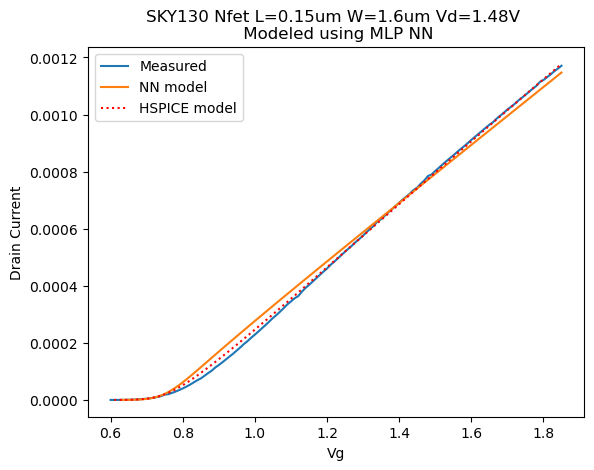

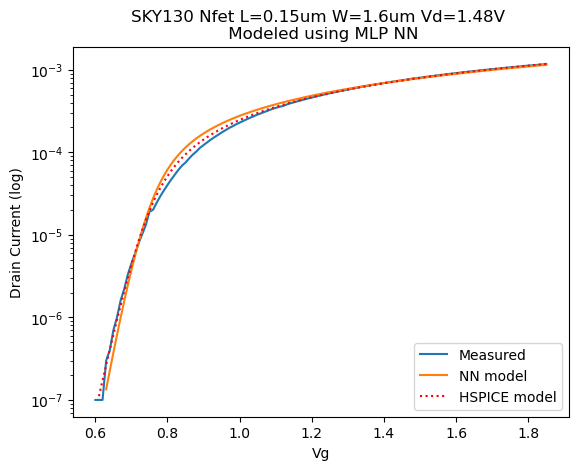

In [91]:
filename2 = 'test_measurements/vgs_prediction.dat'
df2 = pd.read_csv(filename2, sep=r'\s+', engine='python')
predictedId = df2.iloc[:, 3].to_numpy()
predictedVg = abs(df2.iloc[:, 0].to_numpy())
mask = abs(predictedId) >= noiseFloor
predictedId = predictedId[mask]
predictedVg = predictedVg[mask]

filename = f'{home}/Skywater-130nm-77K-Cryogenic-Models/cryo_data/nmos_FET_len_0p15_wid_1p6/idvg_Vd1p48.csv'
 #actualTestCurve.csv
df2 = pd.read_csv(filename)
actualId = df2.iloc[:, 2].to_numpy()
actualVg = df2.iloc[:, 1].to_numpy()
mask = abs(actualId) >= noiseFloor
actualId = actualId[mask]
actualVg = actualVg[mask]

filename3 = f"{home}/ngspice-skywater-sims/outside_data/hspice.csv" #actualTestCurve.csv
df3 = pd.read_csv(filename3)
roomTempId = abs(df3.iloc[:, 2].to_numpy())
roomTempVg = df3.iloc[:, 0].to_numpy()
mask = abs(roomTempId) >= noiseFloor
roomTempId = roomTempId[mask]
roomTempVg = roomTempVg[mask]

fig = plt.figure()
plt.plot(actualVg, [abs(val) for val in actualId], label = 'Measured')
plt.plot(predictedVg, [abs(val) for val in predictedId], label = 'NN model')
plt.plot(roomTempVg, [abs(val) for val in roomTempId], color='r', linestyle=':', label = 'HSPICE model')
plt.title('SKY130 Nfet L=0.15um W=1.6um Vd=1.48V \n Modeled using MLP NN',fontsize=12)
plt.ylabel('Drain Current')
plt.xlabel('Vg')
plt.legend(loc = 'best')
plt.savefig('plots/predictedVsMeasured_lin.png', dpi= 500)
plt.savefig('plots/predictedVsMeasured_lin.pdf', dpi= 500)

fig = plt.figure()
plt.plot(actualVg, [abs(val) for val in actualId], label = 'Measured')
plt.plot(predictedVg, [abs(val) for val in predictedId], label = 'NN model')
plt.plot(roomTempVg, [abs(val) for val in roomTempId], color='r', linestyle=':', label = 'HSPICE model')
plt.title('SKY130 Nfet L=0.15um W=1.6um Vd=1.48V \n Modeled using MLP NN',fontsize=12)
plt.ylabel('Drain Current (log)')
plt.xlabel('Vg')
plt.legend(loc = 'best')
plt.yscale('log')
plt.savefig('plots/predictedVsMeasured_log.png', dpi= 500)
plt.savefig('plots/predictedVsMeasured_log.pdf', dpi= 500)

In [92]:
def curveRRMS(I_measTot, I_simTot):
    RRMS_numSum = 0
    RRMS_denSum = 0
    N = len(I_measTot)
    
    rmse = np.sqrt(np.mean((np.abs(I_simTot) - np.abs(I_measTot)) ** 2))
    mean_meas = np.mean(np.abs(I_measTot))
    
    RRMS_k = rmse / mean_meas

    
    return RRMS_k
def getCurrentData_N_Vg(sim_path, meas_path, bias_vd, device, sim_cols, meas_cols, meas_skip):

    device = (
     device.lower()
    .replace('fet_', '')
    .replace('p', '.')

    )
    
    noise_csv = f'{home}/ngspice-skywater-sims/RRMS/noise_removal_log_nMOS_77K.csv'
    pmos_noise_data = pd.read_csv(noise_csv, usecols=['folder', 'file', 'noise_floor_A', 'noise_threshold_A', 'noise_cutoff_vgate_V'])
    bias_vd = float(bias_vd)
    matches = pmos_noise_data[pmos_noise_data['folder'].str.strip().str.lower() == device.strip().lower()].reset_index(drop=True)
    extracted_strings = matches['file'].str.extract(r'-drain(-?\d+\.?\d*)')[0]
    drain_vals = pd.to_numeric(extracted_strings, errors='coerce')
    
    valid_mask = drain_vals.notna() & np.isclose(drain_vals.fillna(np.nan), bias_vd, atol=1e-3)
    final_match = matches[valid_mask].reset_index(drop=True)


    cutoff_vg = np.abs(final_match['noise_cutoff_vgate_V']).iloc[0]
    if math.isnan(cutoff_vg):
        cutoff_vg = 0
        id_thrs = 0
    else:
        id_thrs = final_match['noise_threshold_A'].iloc[0]
        #print('exists!!')
        #print(cutoff_vg, vd)
        
    sim_data = np.loadtxt(sim_path, usecols=sim_cols, unpack=True)
    vg_sim, i_sim = sim_data[0], sim_data[1]

    # Load measurement: meas_cols[0] is voltage, meas_cols[1] is Id
    meas_data = np.loadtxt(
        meas_path,
        skiprows=1,
        delimiter=",",
        usecols=meas_cols,
        unpack=True,
    )
    vg_meas, i_meas = meas_data[0], meas_data[1]
    if np.abs(cutoff_vg) > 0:
        idx_m = np.argmin(np.abs(np.array(vg_meas) - cutoff_vg))
        idx_s = np.argmin(np.abs(np.array(vg_sim) - cutoff_vg))
    
        #if (i_sim[idx_s + 1] > id_thrs) & (i_meas[idx_m + 1] > id_thrs):
        if idx_m:
            #i_sim_clean = np.zeros(len(i_sim))
            i_sim_clean = i_sim[(idx_s + 1):]
            #i_meas_clean = np.zeros(len(i_meas))
            i_meas_clean = i_meas[(idx_m + 1):]
            #print('m idx', (idx_m+1))
            #print('s idx', (idx_s+1))
    
            return i_sim_clean, i_meas_clean
        else:
            return i_sim, i_meas
    else:
            return i_sim, i_meas

In [93]:
import pandas as pd
import math

#//single curve rrms

col_s = (0,3)
col_m = (1,2)
vd=1.48
m_di = [{"display_name": "L=0.15u W=1.6u", "meas_dir": "nmos_FET_len_0p15_wid_1p6", 'sim_dir': "l_0p15_w_1p6"}]
m_dir = m_di[0]
device = m_dir["meas_dir"]


I_simVG, I_measVG = getCurrentData_N_Vg(filename2, filename, vd, device, col_s, col_m, 1)


vg_rrms = curveRRMS(I_measVG, I_simVG)
print(vg_rrms)


0.050728211194495866
